### Notebook 6a — Second Case Study: Tuberculosis Chest X-rays (Data Preparation)

> First notebook of the small-dataset case study. It loads the Shenzhen and Montgomery chest X-ray sets (tuberculosis vs normal), checks them, builds the splits and saves a 224 × 224 image cache, so that the next notebooks (generation, training, evaluation) can reuse the pipeline of the pneumonia study.

**Input to attach**: the Kaggle dataset *Pulmonary Chest X-Ray Abnormalities* (Montgomery and Shenzhen sets). No GPU is needed.

**What this notebook does**

1. Finds the images in the attached input and **ignores the lung-mask images** (they share file names with the X-rays).
2. Reads the label from the file name (`..._0.png` = normal, `..._1.png` = tuberculosis) and builds one table with source, patient and label.
3. Runs checks: duplicates, labels, image sizes, intensity differences between the two sources.
4. Splits **Shenzhen** into train / validation / test (stratified by label) and keeps **Montgomery** as an external test set. The two sources are never mixed, so the model cannot learn "which hospital" instead of "which disease".
5. Saves the image cache and the index files.

**Saved** (`/kaggle/working`): `tb_manifest.csv` (all images with split), `cache_tb/<split>.npy` (uint8, N × 224 × 224) and `cache_tb/<split>_index.csv`, plus the summary figures.

### 1. Configuration

In [1]:
import os, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')

SEED = 42
SIZE = 224                          # same input size as the pneumonia study
FRAC_VAL, FRAC_TEST = 0.15, 0.25    # Shenzhen split: 60% train, 15% validation, 25% test
INPUT_ROOT, WORK = '/kaggle/input', Path('/kaggle/working')
CACHE = WORK / 'cache_tb'; CACHE.mkdir(parents=True, exist_ok=True)
rng = np.random.RandomState(SEED)

### 2. Find the Images

The attached dataset contains, for each source, the X-ray images and also the lung masks, which have the same file names. Everything under a folder with `mask` in its name is therefore excluded. File names follow the pattern `CHNCXR_0001_0.png` (Shenzhen) and `MCUCXR_0001_0.png` (Montgomery); the last digit is the label.

In [2]:
PAT = {'shenzhen': re.compile(r'^CHNCXR_(\d+)_([01])\.(png|jpg|jpeg)$', re.I), 'montgomery': re.compile(r'^MCUCXR_(\d+)_([01])\.(png|jpg|jpeg)$', re.I)}
rows, n_mask, n_all = [], 0, 0
for cur, dirs, files in os.walk(INPUT_ROOT):
    is_mask = 'mask' in cur.lower()
    for f in files:
        for src, p in PAT.items():
            m = p.match(f)
            if not m: continue
            n_all += 1
            if is_mask: n_mask += 1; continue
            rows.append({'image': f, 'path': os.path.join(cur, f), 'source': src, 'number': int(m.group(1)), 'label': int(m.group(2))})
man = pd.DataFrame(rows)
print(f'{n_all:,} files match the naming pattern, {n_mask:,} are mask images (excluded), {len(man):,} X-ray images kept')
assert len(man), 'No images found: attach the dataset "Pulmonary Chest X-Ray Abnormalities" (look at the folder listing below)'
if man.duplicated('image').any():                                 # the same file listed twice (for example a copy of the folders)
    print('duplicated file names:', int(man.duplicated('image').sum()), '-> keeping the first copy'); man = man.drop_duplicates('image')
man['patient'] = man['source'] + '_' + man['number'].astype(str).str.zfill(4)      # one image per patient in these sets (checked below)
print(man.groupby('source')['label'].agg(images='size', tuberculosis='sum').assign(normal=lambda d: d.images - d.tuberculosis).to_string())
assert man['patient'].is_unique, 'a patient appears more than once: the split must be done by patient'

1,076 files match the naming pattern, 276 are mask images (excluded), 800 X-ray images kept
            images  tuberculosis  normal
source                                  
montgomery     138            58      80
shenzhen       662           336     326


### 3. Checks

* **Image sizes and mode**: the two sources have different sizes and aspect ratios; the images are padded to a square (black) before resizing, so the anatomy is not stretched.
* **Intensity**: the mean and contrast of each source. A large difference between the sources is the reason not to mix them.

In [3]:
def info(p):
    with Image.open(p) as im: return im.size[0], im.size[1], im.mode
t0 = time.time()
with ThreadPoolExecutor(8) as ex: meta = list(ex.map(info, man['path']))
man[['width', 'height', 'mode']] = pd.DataFrame(meta, index=man.index)
print(man.groupby('source')[['width', 'height']].agg(['min', 'median', 'max']).to_string())
print(man.groupby('source')['mode'].value_counts().to_string(), f'\n({time.time() - t0:.0f} s)')

           width               height              
             min  median   max    min  median   max
source                                             
montgomery  4020  4020.0  4892   4020  4892.0  4892
shenzhen    1130  2744.0  3001    948  2937.0  3001
source      mode
montgomery  L       138
shenzhen    P       635
            RGB      27 
(2 s)


### 4. Splits

Shenzhen is split into train / validation / test, stratified by label. Montgomery is kept whole as an **external test set** (a different hospital and scanner). With so few images, the test sets have only a few dozen positives, so the confidence intervals in the final evaluation will be wide; this is a limitation to state in the thesis.

In [4]:
man['split'] = ''
sz = man['source'] == 'shenzhen'
idx = man.index[sz]
tr_val, te = train_test_split(idx, test_size=FRAC_TEST, stratify=man.loc[idx, 'label'], random_state=SEED)
tr, va = train_test_split(tr_val, test_size=FRAC_VAL / (1 - FRAC_TEST), stratify=man.loc[tr_val, 'label'], random_state=SEED)
man.loc[tr, 'split'] = 'train'; man.loc[va, 'split'] = 'val'; man.loc[te, 'split'] = 'test'
man.loc[man['source'] == 'montgomery', 'split'] = 'test_external'
assert (man['split'] != '').all() and man['patient'].is_unique
tab = man.groupby('split')['label'].agg(images='size', tuberculosis='sum').assign(normal=lambda d: d.images - d.tuberculosis, prevalence=lambda d: (d.tuberculosis / d.images).round(3))
print(tab.to_string())
man.drop(columns=['path']).to_csv(WORK / 'tb_manifest.csv', index=False)

               images  tuberculosis  normal  prevalence
split                                                  
test              166            84      82       0.506
test_external     138            58      80       0.420
train             396           201     195       0.508
val               100            51      49       0.510


### 5. Image Cache

Each image is converted to grey scale, padded to a square and resized to 224 × 224 with Lanczos resampling (the same resampling as the pneumonia study), and saved as one `uint8` array per split.

In [5]:
def load(p):
    im = Image.open(p).convert('L'); w, h = im.size; s = max(w, h)
    sq = Image.new('L', (s, s), 0); sq.paste(im, ((s - w) // 2, (s - h) // 2))             # pad to a square, anatomy not stretched
    return np.asarray(sq.resize((SIZE, SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)

X = {}
for sp in ('train', 'val', 'test', 'test_external'):
    d = man[man['split'] == sp].sort_values('image').reset_index(drop=True)
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex: X[sp] = np.stack(list(ex.map(load, d['path'])))
    np.save(CACHE / f'{sp}.npy', X[sp]); d.drop(columns=['path']).to_csv(CACHE / f'{sp}_index.csv', index=False)
    print(f'{sp:14s} {X[sp].shape}  ({time.time() - t0:.0f} s)')

train          (396, 224, 224)  (29 s)
val            (100, 224, 224)  (8 s)
test           (166, 224, 224)  (13 s)
test_external  (138, 224, 224)  (25 s)


### 6. Visual Check and Source Comparison

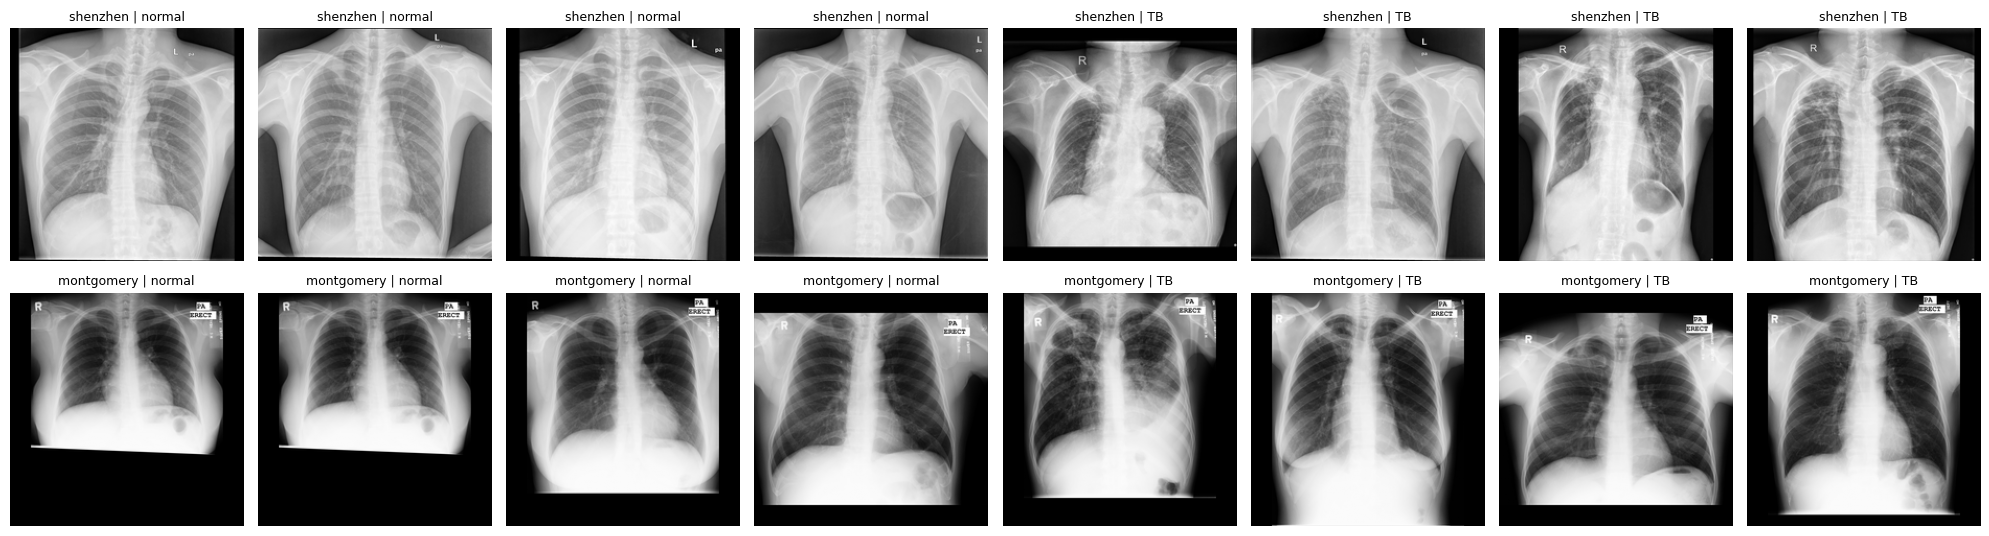

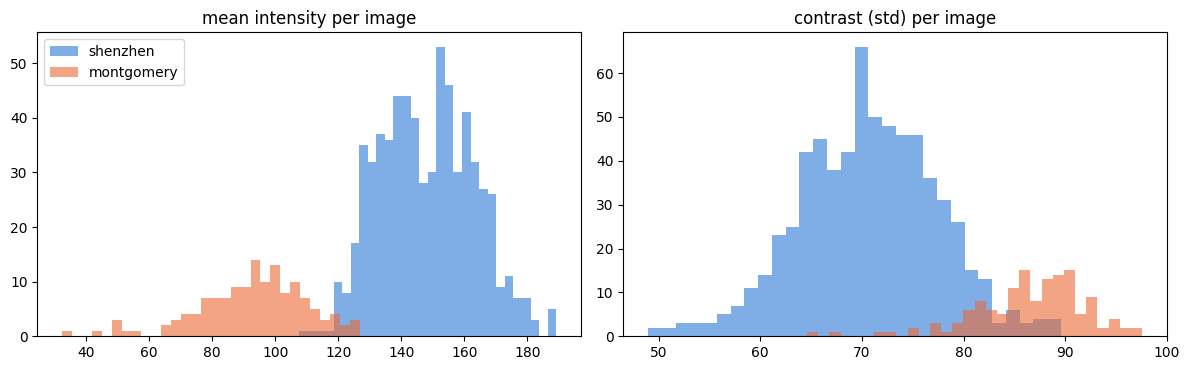

In [6]:
fig, ax = plt.subplots(2, 8, figsize=(20, 5.6))
for r, src in enumerate(('shenzhen', 'montgomery')):
    for c, lab in enumerate((0, 0, 0, 0, 1, 1, 1, 1)):
        d = man[(man['source'] == src) & (man['label'] == lab)]
        row = d.iloc[rng.randint(len(d))]
        ax[r, c].imshow(load(row['path']), cmap='gray'); ax[r, c].axis('off'); ax[r, c].set_title(f"{src} | {'TB' if lab else 'normal'}", fontsize=9)
plt.tight_layout(); plt.savefig(WORK / 'fig_samples.png', dpi=130); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for src, col in (('shenzhen', '#2a78d6'), ('montgomery', '#eb6834')):
    xs = np.concatenate([X[sp][pd.read_csv(CACHE / f'{sp}_index.csv')['source'].values == src] for sp in X])
    flat = xs.reshape(len(xs), -1).astype(np.float32)
    ax[0].hist(flat.mean(1), bins=30, alpha=0.6, color=col, label=src); ax[1].hist(flat.std(1), bins=30, alpha=0.6, color=col, label=src)
ax[0].set_title('mean intensity per image'); ax[1].set_title('contrast (std) per image'); ax[0].legend()
plt.tight_layout(); plt.savefig(WORK / 'fig_sources.png', dpi=130); plt.show()

### 7. Summary

Files saved in `/kaggle/working`. Next notebooks of this case study:

* **6b** — synthetic image generation for the small training set (DC-GAN trained on the Shenzhen training positives, and RoentGen-v2 prompts for tuberculosis findings).
* **6c** — classifier training with the same scenarios as the pneumonia study.
* **6d** — final evaluation (same as Notebook 5), including the external test on Montgomery.

In [7]:
print(sorted(p.name for p in WORK.iterdir())); print(sorted(p.name for p in CACHE.iterdir()))

['__notebook__.ipynb', 'cache_tb', 'fig_samples.png', 'fig_sources.png', 'tb_manifest.csv']
['test.npy', 'test_external.npy', 'test_external_index.csv', 'test_index.csv', 'train.npy', 'train_index.csv', 'val.npy', 'val_index.csv']
